# Thesis Fig. 3 — five kernel families

Reproduction of Tepper (2026), Fig. 3 (thesis PDF p. 45; printed p. 38), panel by panel.

> Rows: point, Gaussian, Gabor, box B⁰, cubic B-spline B³. Columns: kernel k(r); normalized spectrum |k̂_m|/|k̂|_max
> with floor; per-mode convergence of the weights over training epochs; learned weights against w*; readout against
> target.

**Panels:** A kernels · B spectra · C per-mode convergence · D weights over epochs · E readout vs target.

**Acceptance (spec 6A.6):** per-mode convergence rates match eq. 3.19 within 5%.

**Parameters [D11]:** see `configs/thesis/fig3.yaml`. Kernels are unit-integral (§2.1). The delta rule (eq. 3.18)
runs in its expected (mean-field) form, one averaged sweep over the N positions per epoch, with decay λ/T so that its
fixed point is the eq. 3.13 ridge solution (REPORT discrepancy 2). The figure's target repeats with period π, so only
even harmonics carry power; odd modes (m = 1, 9) stay at zero, as in the figure.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig3"
cfg = load_config(FIG)
N, decay, eta = cfg["N"], cfg["decay"], cfg["eta"]
ring, sched = th.Ring(N), th.Schedule(N, 1)
LABELS = list(cfg["families"])
kernels = [th.Kernel.from_family(f, N, **p) for f, p in cfg["families"].values()]
rng = np.random.default_rng(cfg["seed"])
tg = cfg["target"]
j = np.arange(1, tg["n_harmonics"] + 1)
b = rng.normal(size=j.size) * np.exp(-tg["decay"] * j)
y = (b[None, :] * np.cos(2 * np.outer(sched.positions, j))).sum(1)
y = y / np.abs(y).max()

## Panel A — kernel profiles k(r)

In [2]:
save_data(FIG, "A_kernels", params={"families": cfg["families"]}, K=np.stack([k.values for k in kernels]), r=ring.centred_positions)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig3/A_kernels.npz')

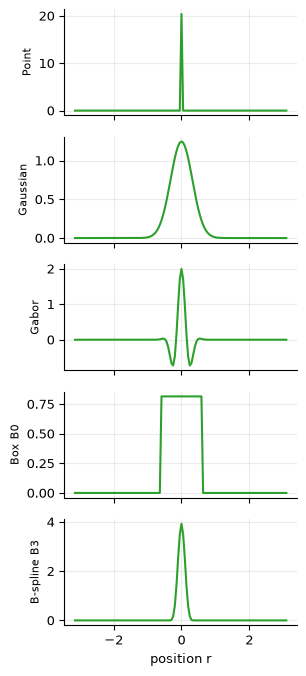

In [3]:
d = load_data(FIG, "A_kernels"); o = np.argsort(d["r"])
fig, axs = plt.subplots(5, 1, figsize=(3, 8), sharex=True)
for ax, kv, lab in zip(axs, d["K"], LABELS):
    ax.plot(d["r"][o], kv[o], color="tab:green"); ax.set_ylabel(lab, fontsize=8)
axs[-1].set_xlabel("position r")
save_figure(FIG, "A_kernels", fig); plt.show()

## Panel B — normalized spectrum |k̂_m| / |k̂|_max with floor

The figure's r_k labels mark the largest mode above the floor, a cutoff index. Eq. 4.8's count over signed modes is
reported alongside.

In [4]:
spec = np.stack([np.abs(k.spectrum())[: N // 2 + 1] for k in kernels])
spec = spec / spec.max(1, keepdims=True)
cut = np.array([np.nonzero(s > cfg["floor"])[0].max() for s in spec])
cut[0] = N  # point kernel: every mode above the floor; the figure labels this r_k = 128 = N
rank48 = np.array([k.effective_rank(cfg["floor"], "max") for k in kernels])
save_data(FIG, "B_spectra", params={"floor": cfg["floor"]}, spec=spec, cutoff=cut, rank_eq48=rank48,
          figure=np.array(cfg["figure_cutoffs"]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig3/B_spectra.npz')

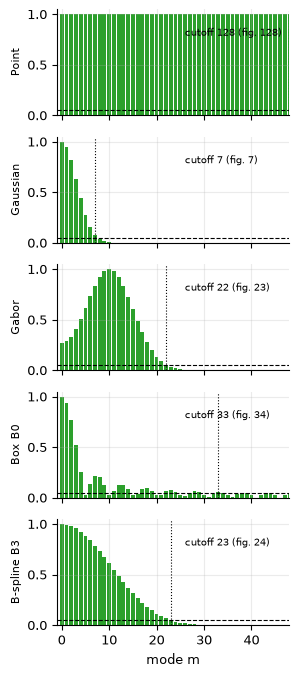

cutoffs    : [128   7  22  33  23]
figure     : [128   7  23  34  24]
eq. 4.8 r_k: [128  15  45  43  47]


In [5]:
d = load_data(FIG, "B_spectra")
fig, axs = plt.subplots(5, 1, figsize=(3, 8), sharex=True)
for ax, s, c, f, lab in zip(axs, d["spec"], d["cutoff"], d["figure"], LABELS):
    ax.bar(np.arange(s.size), s, color="tab:green", width=0.8)
    ax.axhline(cfg["floor"], ls="--", color="k", lw=0.8)
    ax.axvline(min(c, 48), ls=":", color="k", lw=0.8)
    ax.text(0.55, 0.75, f"cutoff {c} (fig. {f})", transform=ax.transAxes, fontsize=7)
    ax.set_xlim(-1, 48); ax.set_ylabel(lab, fontsize=8)
axs[-1].set_xlabel("mode m")
save_figure(FIG, "B_spectra", fig); plt.show()
print("cutoffs    :", d["cutoff"]); print("figure     :", d["figure"]); print("eq. 4.8 r_k:", d["rank_eq48"])

## Panel C — per-mode convergence

Real Fourier coefficient (unitary DFT) of the weights at m = 1, 2, 6, 9 over epochs; dashed lines are the ridge
values. Rates are fitted on |ŵ_m(n) − ŵ*_m| and compared with eq. 3.19, τ⁻¹ = η(a_m/T + λ_d).

In [6]:
modes = np.array(cfg["modes"]); E = cfg["epochs"]
W_modes = np.zeros((5, E + 1, modes.size)); W_star_modes = np.zeros((5, modes.size))
snaps = np.array(cfg["snapshots"]); W_snap = np.zeros((5, snaps.size, N)); W_star = np.zeros((5, N))
rates_fit = np.full((5, modes.size), np.nan); rates_pred = np.zeros((5, modes.size)); YH = np.zeros((5, N))
for f, k in enumerate(kernels):
    X = th.design_matrix(k, sched)
    ws = th.ridge_readout(X, y, decay); W_star[f] = ws
    W_star_modes[f] = np.real(th.unitary_dft(ws))[modes]
    dr = th.DeltaRule(N, eta, decay, N)
    traj = [dr.w.copy()]
    for n in range(E):
        traj.append(dr.batch_epoch(X, y).copy())
    traj = np.asarray(traj)
    W_modes[f] = np.real(th.unitary_dft(traj, axis=1))[:, modes]
    W_snap[f] = traj[snaps]
    YH[f] = X @ traj[-1]
    a = np.abs(k.spectrum()) ** 2
    rates_pred[f] = th.delta_rule_rates(a[modes], eta, dr.decay_d, N)
    for q, m in enumerate(modes):
        dev = np.abs(np.fft.fft(traj - ws, axis=1)[:, m])
        if dev[0] < 1e-8 * max(np.abs(np.fft.fft(ws)).max(), 1e-12):
            continue  # mode carries no target power (odd modes) -> nothing to fit
        good = np.nonzero(dev > 1e-6 * dev[0])[0]
        n_fit = good[: max(10, good.size // 2)]
        rates_fit[f, q] = 1 - np.exp(np.polyfit(n_fit, np.log(dev[n_fit]), 1)[0])
save_data(FIG, "C_convergence", params={"eta": eta, "decay": decay, "modes": modes}, W_modes=W_modes,
          W_star_modes=W_star_modes, rates_fit=rates_fit, rates_pred=rates_pred)
save_data(FIG, "D_weights", params={"snapshots": snaps}, W_snap=W_snap, W_star=W_star, r=ring.positions)
save_data(FIG, "E_readout", y=y, YH=YH, c=sched.positions)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig3/E_readout.npz')

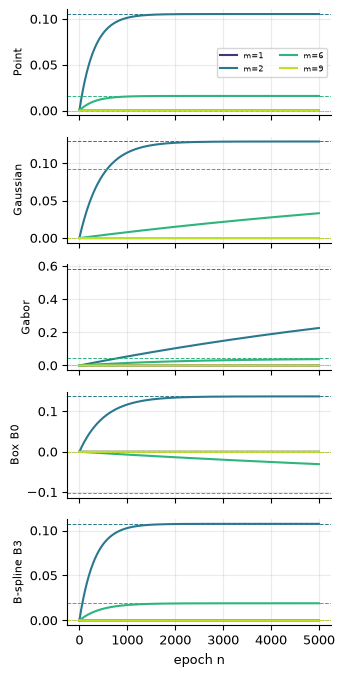

fitted rates:
 [[       nan 3.2501e-03 3.2501e-03        nan]
 [       nan 2.1604e-03 8.9071e-05        nan]
 [       nan 9.8330e-05 4.4228e-04        nan]
 [       nan 1.9179e-03 7.1496e-05        nan]
 [       nan 3.1274e-03 2.2927e-03        nan]]
eq. 3.19:
 [[3.2501e-03 3.2501e-03 3.2501e-03 3.2501e-03]
 [2.9345e-03 2.1604e-03 8.9071e-05 8.6228e-06]
 [7.4495e-05 9.8330e-05 4.4228e-04 7.8776e-04]
 [2.8636e-03 1.9179e-03 7.1496e-05 5.9193e-05]
 [3.2190e-03 3.1274e-03 2.2927e-03 1.4701e-03]]


In [7]:
d = load_data(FIG, "C_convergence")
cols = plt.cm.viridis(np.linspace(0.15, 0.9, len(modes)))
fig, axs = plt.subplots(5, 1, figsize=(3.4, 8), sharex=True)
for f, ax in enumerate(axs):
    for q, m in enumerate(modes):
        ax.plot(d["W_modes"][f, :, q], color=cols[q], label=f"m={m}")
        ax.axhline(d["W_star_modes"][f, q], ls="--", color=cols[q], lw=0.7)
    ax.set_ylabel(LABELS[f], fontsize=8)
axs[0].legend(fontsize=6, ncol=2); axs[-1].set_xlabel("epoch n")
save_figure(FIG, "C_convergence", fig); plt.show()
with np.printoptions(precision=4, suppress=False):
    print("fitted rates:\n", d["rates_fit"]); print("eq. 3.19:\n", d["rates_pred"])

## Panel D — weights over epochs against w*

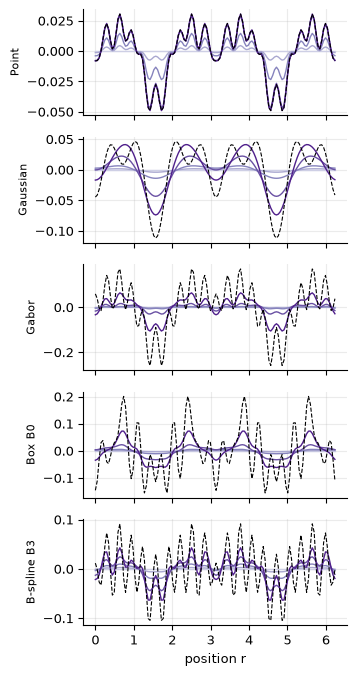

In [8]:
d = load_data(FIG, "D_weights")
fig, axs = plt.subplots(5, 1, figsize=(3.4, 8), sharex=True)
sh = plt.cm.Purples(np.linspace(0.3, 0.9, d["W_snap"].shape[1]))
for f, ax in enumerate(axs):
    for s in range(d["W_snap"].shape[1]):
        ax.plot(d["r"], d["W_snap"][f, s], color=sh[s], lw=1)
    ax.plot(d["r"], d["W_star"][f], "k--", lw=0.8)
    ax.set_ylabel(LABELS[f], fontsize=8)
axs[-1].set_xlabel("position r")
save_figure(FIG, "D_weights", fig); plt.show()

## Panel E — readout against target (after the last epoch)

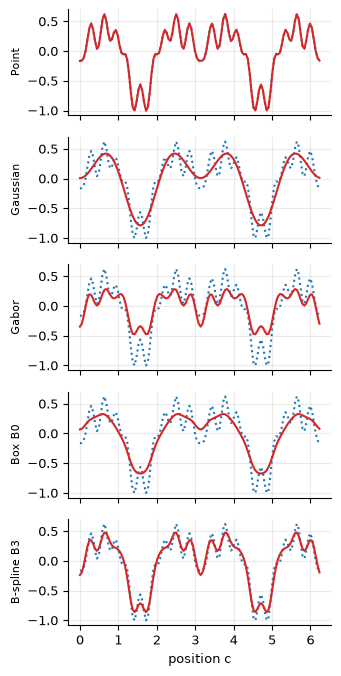

In [9]:
d = load_data(FIG, "E_readout")
fig, axs = plt.subplots(5, 1, figsize=(3.4, 8), sharex=True)
for f, ax in enumerate(axs):
    ax.plot(d["c"], d["y"], ":", color="tab:blue"); ax.plot(d["c"], d["YH"][f], color="tab:red")
    ax.set_ylabel(LABELS[f], fontsize=8)
axs[-1].set_xlabel("position c")
save_figure(FIG, "E_readout", fig); plt.show()

## Acceptance

In [10]:
d = load_data(FIG, "C_convergence")
rel = np.abs(d["rates_fit"] - d["rates_pred"]) / d["rates_pred"]
ok = np.isfinite(rel)
checks = [{"item": "per-mode convergence rates match eq. 3.19", "criterion": "max relative error < 5% over fitted (family, mode)",
           "value": float(np.nanmax(rel)), "n_fitted": int(ok.sum()), "passed": bool(np.nanmax(rel) < 0.05)}]
b = load_data(FIG, "B_spectra")
checks.append({"item": "spectral cutoffs vs figure labels (qualitative)", "criterion": "reported only",
               "value": {"reproduced": b["cutoff"], "figure": b["figure"]}, "passed": None})
record_checks(FIG, checks)
for c in checks: print(c)

{'item': 'per-mode convergence rates match eq. 3.19', 'criterion': 'max relative error < 5% over fitted (family, mode)', 'value': 6.092312806726119e-13, 'n_fitted': 10, 'passed': True}
{'item': 'spectral cutoffs vs figure labels (qualitative)', 'criterion': 'reported only', 'value': {'reproduced': array([128,   7,  22,  33,  23]), 'figure': array([128,   7,  23,  34,  24])}, 'passed': None}
